### Step 1: Dataset Loading & Exploratory Data Analysis
* 1.1  Load & Inspect the Dataset

In [1]:
# import kagglehub

# # Download latest version
# path = kagglehub.dataset_download("vjchoudhary7/customer-segmentation-tutorial-in-python")

# print("Path to dataset files:", path)

Load Mall_Customers.csv using pandas.

In [2]:
import pandas as pd

df=pd.read_csv('Mall_Customers.csv')

Print .shape, .info(), and .head(10)

In [ ]:
print(df.shape)

(200, 5)


In [ ]:
print(df.info())

<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   CustomerID              200 non-null    int64
 1   Gender                  200 non-null    str  
 2   Age                     200 non-null    int64
 3   Annual Income (k$)      200 non-null    int64
 4   Spending Score (1-100)  200 non-null    int64
dtypes: int64(4), str(1)
memory usage: 7.9 KB
None


In [ ]:
df.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


Rename columns for clarity

In [ ]:
df=df.rename(columns={'Annual Income (k$)':'Annual Income','Spending Score (1-100)':'Spending Score'})
df.columns

Index(['CustomerID', 'Gender', 'Age', 'Annual Income', 'Spending Score'], dtype='str')

Check for missing values (.isnull().sum()).

In [ ]:
df.isnull().sum()

CustomerID        0
Gender            0
Age               0
Annual Income     0
Spending Score    0
dtype: int64

Report: number of male vs female customers

In [ ]:
df['Gender'].value_counts()

Gender
Female    112
Male       88
Name: count, dtype: int64

- 1.2  Univariate Analysis 

Plot histograms for: Age, AnnualIncome, SpendingScore. Comment on the shape of each distribution.


Text(0.5, 0, 'Age')

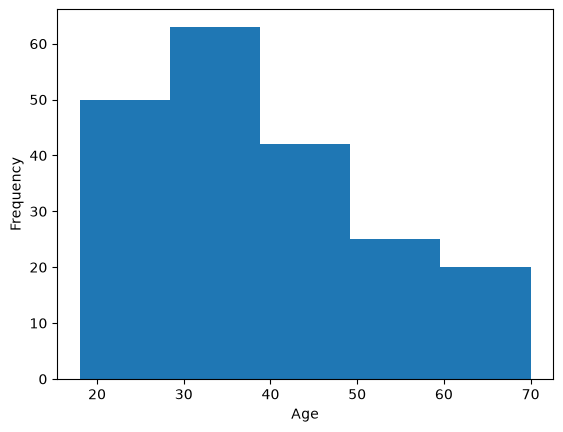

In [ ]:
import matplotlib.pyplot as plt

df['Age'].plot(kind='hist',bins=5)
plt.xlabel('Age')

-It is not normally distribute

Text(0.5, 0, 'Annual Income')

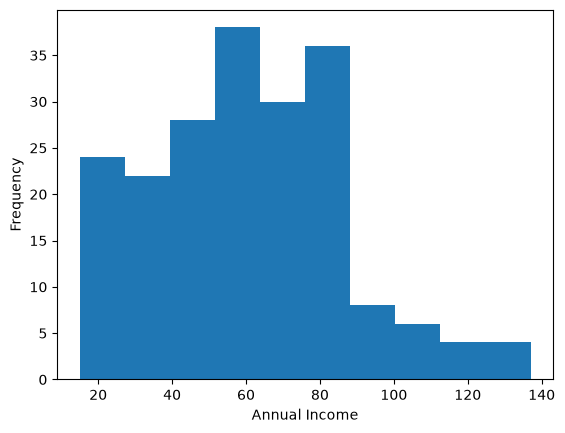

In [ ]:
df['Annual Income'].plot(kind='hist')
plt.xlabel('Annual Income')

-it is right skewed

Text(0.5, 0, 'Spending Score')

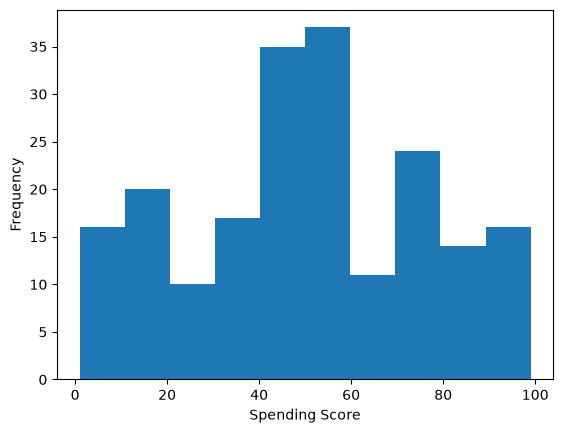

In [ ]:
df['Spending Score'].plot(kind='hist')
plt.xlabel('Spending Score')

-It is not normally distributed

Plot boxplots for: Age, AnnualIncome, SpendingScore. Identify any visible outliers.

Text(0.5, 1.0, 'Spending Score')

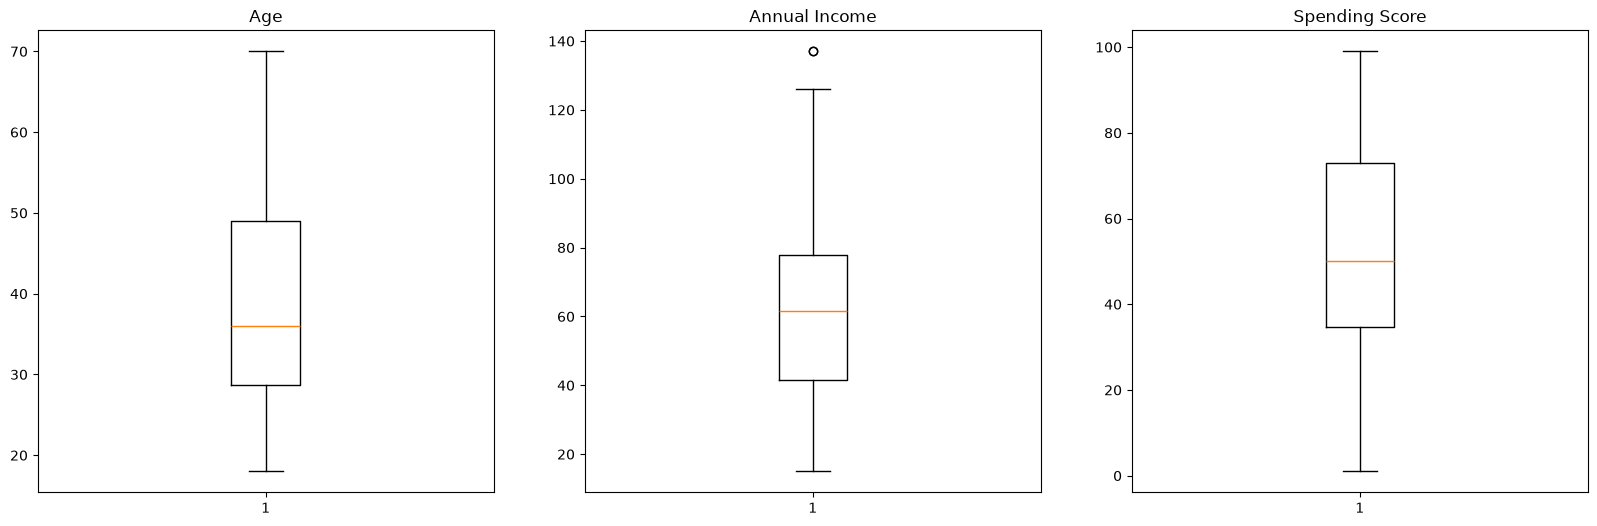

In [ ]:
fig,(ax1,ax2,ax3)=plt.subplots(1,3,figsize=(20,6))
ax1.boxplot(df['Age'])
ax1.set_title('Age')
ax2.boxplot(df['Annual Income'])
ax2.set_title('Annual Income')
ax3.boxplot(df['Spending Score'])
ax3.set_title('Spending Score')

-There is an outlier in column- Annual Income. Above $130k.

Plot a countplot for Gender. Is the dataset balanced by gender?

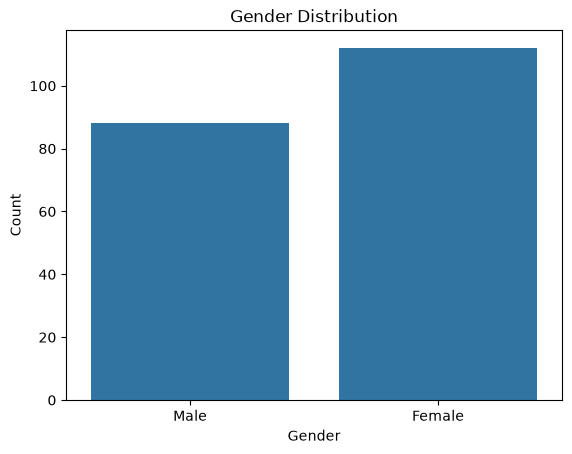

In [ ]:
import seaborn as sns

sns.countplot(x='Gender', data=df)
plt.title("Gender Distribution")
plt.xlabel("Gender")
plt.ylabel("Count")
plt.show()

Is the dataset balanced by gender? 

-No. The dataset is slightly imbalanced:      

Female: 112 (56%)   
Male: 88 (44%)

* 1.3  Bivariate Analysis 

Scatter plot: AnnualIncome vs SpendingScore. Do you visually spot natural groupings?

Text(0, 0.5, 'Spending Score')

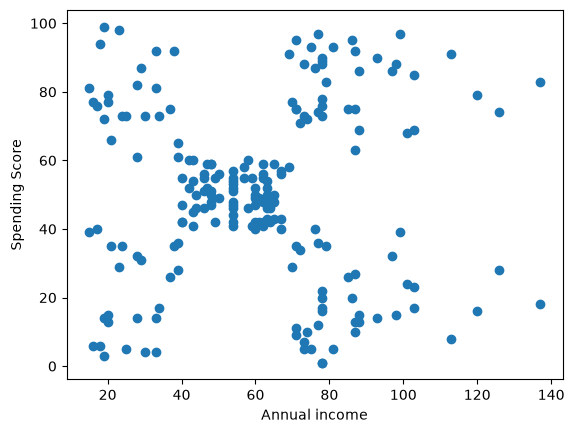

In [ ]:
plt.scatter(df['Annual Income'], df['Spending Score'])
plt.xlabel('Annual income')
plt.ylabel('Spending Score')

-Yes we can see 5 natural groupings.

Scatter plot: Age vs SpendingScore, coloured by Gender.

Text(0, 0.5, 'Spending Score')

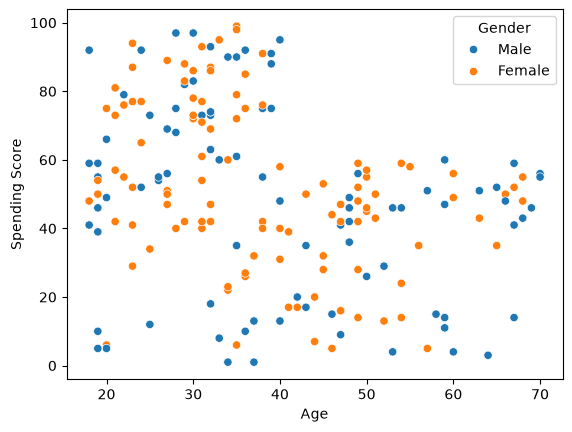

In [ ]:
sns.scatterplot(x='Age',y='Spending Score',hue='Gender',data=df)
plt.xlabel('Age')
plt.ylabel('Spending Score')
# plt.legend(df['Gender'])

Scatter plot: Age vs AnnualIncome, coloured by Gender.

Text(0, 0.5, 'Annual Income')

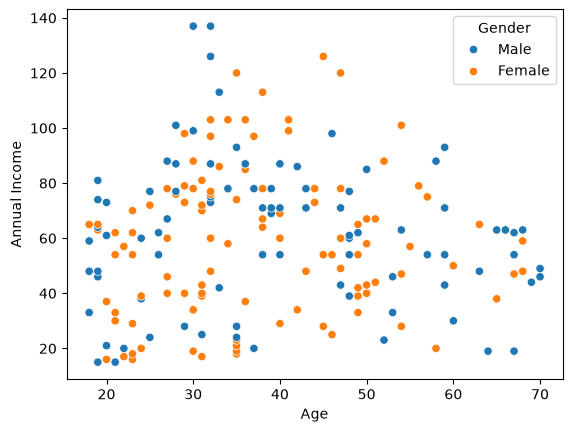

In [ ]:
sns.scatterplot(x='Age',y='Annual Income',hue='Gender',data=df)
plt.xlabel('Age')
plt.ylabel('Annual Income')

Compute and print the correlation matrix for all numerical columns. Plot it as a heatmap.

<Axes: >

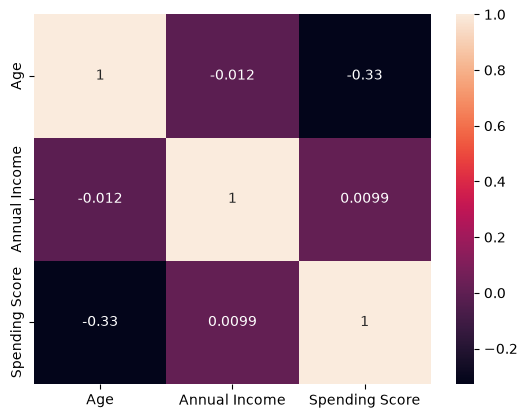

In [ ]:
sns.heatmap(df[['Age','Annual Income','Spending Score']].corr(),annot=True)

- 1.4  Gender-Wise Summary 

Compute mean Age, AnnualIncome, and SpendingScore separately for Male and Female customers


In [ ]:
fd=df['Age'].groupby(df['Gender']).mean()
fd2=df['Annual Income'].groupby(df['Gender']).mean()
fd3=df['Spending Score'].groupby(df['Gender']).mean()

fdpd=pd.DataFrame({'Mean age':fd,'Mean Income':fd2,'Mean Spending':fd3})
fdpd

,Mean age,Mean Income,Mean Spending
Gender,,,
Female,38.098214,59.250000,51.526786
Male,39.806818,62.227273,48.511364


Present this as a grouped bar chart: Gender vs each of the three metrics.

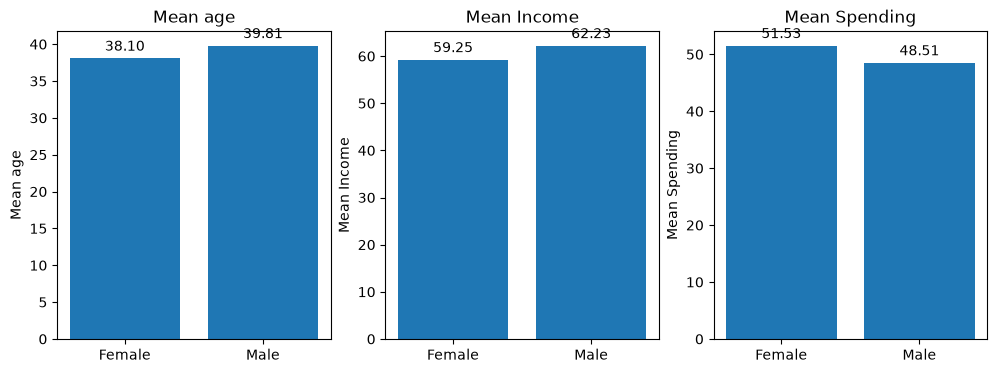

In [ ]:
metrics = fdpd.columns.tolist()
fig, axes = plt.subplots(1, len(metrics), figsize=(4*len(metrics),4))

if len(metrics) == 1:
    axes = [axes]

for ax, metric in zip(axes, metrics):
    bars = ax.bar(fdpd.index, fdpd[metric])
    ax.set_title(metric)
    ax.set_ylabel(metric)
    ax.bar_label(bars, fmt='%.2f', padding=3)

Write 2–3 sentences summarising any meaningful gender-based differences observed.

-Male customers have a slightly higher average age and slightly higher annual income than female customers. 

-Female customers have a higher average spending score, indicating they tend to spend a little more despite having a slightly lower average income.

### Step 2: Feature Engineering & Preprocessing  
* 2.1  Encode Categorical Feature  

Apply Label Encoding to Gender: Female → 0, Male → 1. Store as Gender_enc.


In [ ]:
from sklearn.preprocessing import LabelEncoder

enc=LabelEncoder()
df['gender_enc']=enc.fit_transform(df['Gender'])
df[['gender_enc','Gender']]

,gender_enc,Gender
0,1,Male
1,1,Male
2,0,Female
3,0,Female
4,0,Female
...,...,...
195,0,Female
196,0,Female
197,1,Male
198,1,Male


* 2.2  Engineer New Features  

Create IncomeGroup: bin AnnualIncome into 3 groups using pd.qcut — 'Low', 'Medium', 'High' (equal-frequency bins).


In [ ]:
df['IncomeGroup'] = pd.qcut(df['Annual Income'],q=3,labels=['Low', 'Medium', 'High'])

Create AgeGroup: bin Age into 4 groups — 'Young' (18–25), 'Adult' (26–40), 'Middle-Aged' (41–55), 'Senior' (55+) using pd.cut

In [ ]:
df['AgeGroup']=pd.cut(df['Age'],bins=[18, 25, 40, 55, float('inf')],labels=['Young','Adult','Middle-Aged','Senior'],include_lowest=True)

Create SpendingCategory: bin SpendingScore into 3 groups — 'Low' (1–33), 'Medium' (34–66), 'High' (67–100)

In [ ]:
df['SpendingScoreGroup']=pd.cut(df['Spending Score'],bins=[0, 33, 66, 100],labels=['Low','Medium','High'],include_lowest=True)

In [ ]:
df.head()

,CustomerID,Gender,Age,Annual Income,Spending Score,gender_enc,IncomeGroup,AgeGroup,SpendingScoreGroup
0,1,Male,19,15,39,1,Low,Young,Medium
1,2,Male,21,15,81,1,Low,Young,High
2,3,Female,20,16,6,0,Low,Young,Low
3,4,Female,23,16,77,0,Low,Young,High
4,5,Female,31,17,40,0,Low,Adult,Medium


Print value_counts for each new engineered column. Are the bins roughly balanced?

In [ ]:
print(df['IncomeGroup'].value_counts())
print()

print(df['AgeGroup'].value_counts())
print()

print(df['SpendingScoreGroup'].value_counts())

IncomeGroup
Low       70
High      66
Medium    64
Name: count, dtype: int64

AgeGroup
Adult          84
Middle-Aged    49
Young          38
Senior         29
Name: count, dtype: int64

SpendingScoreGroup
Medium    94
High      57
Low       49
Name: count, dtype: int64


In [ ]:
print("\nIncomeGroup (%)")
print(df['IncomeGroup'].value_counts(normalize=True) * 100)

print("\nAgeGroup (%)")
print(df['AgeGroup'].value_counts(normalize=True) * 100)

print("\SpendingScoreGroup (%)")
print(df['SpendingScoreGroup'].value_counts(normalize=True) * 100)


IncomeGroup (%)
IncomeGroup
Low       35.0
High      33.0
Medium    32.0
Name: proportion, dtype: float64

AgeGroup (%)
AgeGroup
Adult          42.0
Middle-Aged    24.5
Young          19.0
Senior         14.5
Name: proportion, dtype: float64
\SpendingScoreGroup (%)
SpendingScoreGroup
Medium    47.0
High      28.5
Low       24.5
Name: proportion, dtype: float64


<>:7: SyntaxWarning: "\S" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\S"? A raw string is also an option.
<>:7: SyntaxWarning: "\S" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\S"? A raw string is also an option.
C:\Users\admin\AppData\Local\Temp\ipykernel_18692\1277960929.py:7: SyntaxWarning: "\S" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\S"? A raw string is also an option.
  print("\SpendingScoreGroup (%)")


-IncomeGroup: Since it is created using pd.qcut(), the three groups (Low, Medium, High) will have nearly equal numbers of customers, so the bins are balanced.  

-AgeGroup: Created using fixed intervals (pd.cut), so the group sizes may not be balanced.  

-SpendingCategory: Also created using fixed intervals (pd.cut), so the distribution may not be perfectly balanced because the spending scores are not uniformly distributed.

### 2.3  Select Features for Clustering  

* You will run two clustering experiments using different feature sets:  

Experiment A — 2D Clustering: features = [AnnualIncome, SpendingScore] (classic two-feature setup).


In [ ]:
X_2d = df[['Annual Income', 'Spending Score']]
print(X_2d.head())

   Annual Income  Spending Score
0             15              39
1             15              81
2             16               6
3             16              77
4             17              40


Experiment B — 5D Clustering: features = [Age, AnnualIncome, SpendingScore, Gender_enc] (richer multi-dimensional setup)

In [ ]:
X_5d = df[['Age','Annual Income','Spending Score','gender_enc']]
print(X_5d.head())

   Age  Annual Income  Spending Score  gender_enc
0   19             15              39           1
1   21             15              81           1
2   20             16               6           0
3   23             16              77           0
4   31             17              40           0


Prepare both feature matrices: X_2d and X_5d

In [ ]:
mat1=pd.DataFrame({'Annual Income':X_2d['Annual Income'],'Spending Score':X_2d['Spending Score']})
print('X_2d matrice:')
mat1

X_2d matrice:


,Annual Income,Spending Score
0,15,39
1,15,81
2,16,6
3,16,77
4,17,40
...,...,...
195,120,79
196,126,28
197,126,74
198,137,18


In [ ]:
mat2=pd.DataFrame({'Age':X_5d['Age'],'Annual Income':X_5d['Annual Income'],'Spending Score':X_5d['Spending Score'],'gender_enc':X_5d['gender_enc']})
print('X_5d matrice:')
mat2

X_5d matrice:


,Age,Annual Income,Spending Score,gender_enc
0,19,15,39,1
1,21,15,81,1
2,20,16,6,0
3,23,16,77,0
4,31,17,40,0
...,...,...,...,...
195,35,120,79,0
196,45,126,28,0
197,32,126,74,1
198,32,137,18,1


* 2.4  Scale the Features 

Apply StandardScaler separately to X_2d and X_5d.  

In [ ]:
from sklearn.preprocessing import StandardScaler

scaler_2d = StandardScaler()
X_2d_scaled = scaler_2d.fit_transform(X_2d)

scaler_5d = StandardScaler()
X_5d_scaled=scaler_5d.fit_transform(X_5d)

Store as X_2d_scaled and X_5d_scaled.

In [ ]:
X_2d_scaled = pd.DataFrame(X_2d_scaled,columns=X_2d.columns)
print('X_2d_scaled:\n',X_2d_scaled.head())
print()
X_5d_scaled = pd.DataFrame(X_5d_scaled,columns=X_5d.columns)
print('X_5d_scaled:\n',X_5d_scaled.head())

X_2d_scaled:
    Annual Income  Spending Score
0      -1.738999       -0.434801
1      -1.738999        1.195704
2      -1.700830       -1.715913
3      -1.700830        1.040418
4      -1.662660       -0.395980

X_5d_scaled:
         Age  Annual Income  Spending Score  gender_enc
0 -1.424569      -1.738999       -0.434801    1.128152
1 -1.281035      -1.738999        1.195704    1.128152
2 -1.352802      -1.700830       -1.715913   -0.886405
3 -1.137502      -1.700830        1.040418   -0.886405
4 -0.563369      -1.662660       -0.395980   -0.886405


Print mean and std of each scaled feature to confirm scaling (mean ≈ 0, std ≈ 1)

In [ ]:
X_2d_scaled.describe()

,Annual Income,Spending Score
count,2.000000e+02,2.000000e+02
mean,-2.131628e-16,-1.465494e-16
std,1.002509e+00,1.002509e+00
min,-1.738999e+00,-1.910021e+00
25%,-7.275093e-01,-5.997931e-01
50%,3.587926e-02,-7.764312e-03
75%,6.656748e-01,8.851316e-01
max,2.917671e+00,1.894492e+00


In [ ]:
X_5d_scaled.describe()

,Age,Annual Income,Spending Score,gender_enc
count,2.000000e+02,2.000000e+02,2.000000e+02,2.000000e+02
mean,-1.021405e-16,-2.131628e-16,-1.465494e-16,3.108624e-17
std,1.002509e+00,1.002509e+00,1.002509e+00,1.002509e+00
min,-1.496335e+00,-1.738999e+00,-1.910021e+00,-8.864053e-01
25%,-7.248436e-01,-7.275093e-01,-5.997931e-01,-8.864053e-01
50%,-2.045351e-01,3.587926e-02,-7.764312e-03,-8.864053e-01
75%,7.284319e-01,6.656748e-01,8.851316e-01,1.128152e+00
max,2.235532e+00,2.917671e+00,1.894492e+00,1.128152e+00


### Step 3: K-Means Clustering  

* 3.1  Elbow Method — Find Optimal k  (on X_2d_scaled) 

Run KMeans for k = 2, 3, 4, 5, 6, 7, 8, 9, 10 (init='k-means++', n_init=10, random_state=42).  
For each k, store the Within-Cluster Sum of Squares (inertia_).

In [ ]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

inertia = []
silhouette_scores = []

k_values = range(2, 11)

for k in k_values:
    kmeans = KMeans(n_clusters=k,init='k-means++',n_init=10,random_state=42)
    labels = kmeans.fit_predict(X_2d_scaled)

    inertia.append(kmeans.inertia_)
    silhouette_scores.append(silhouette_score(X_2d_scaled, labels))
    
for k, i, s in zip(k_values, inertia, silhouette_scores):
    print(f"k = {k}, Inertia = {i:.2f}")

k = 2, Inertia = 269.69
k = 3, Inertia = 157.70
k = 4, Inertia = 108.92
k = 5, Inertia = 65.57
k = 6, Inertia = 55.06
k = 7, Inertia = 44.86
k = 8, Inertia = 37.23
k = 9, Inertia = 32.39
k = 10, Inertia = 29.98


Plot the Elbow Curve (k vs Inertia). Mark the elbow point visually with a vertical dashed line

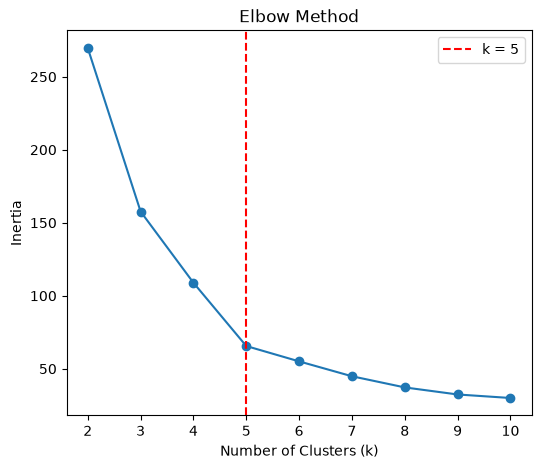

In [ ]:
plt.figure(figsize=(6,5))
plt.plot(k_values, inertia, marker='o')

plt.axvline(x=5,color='red',linestyle='--',label='k = 5')

plt.title("Elbow Method")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Inertia")
plt.legend()

Compute Silhouette Score for each k (2 through 10). Plot k vs Silhouette Score on the same or adjacent figure

k = 2, Silhouette Score = 0.3213
k = 3, Silhouette Score = 0.4666
k = 4, Silhouette Score = 0.4939
k = 5, Silhouette Score = 0.5547
k = 6, Silhouette Score = 0.5399
k = 7, Silhouette Score = 0.5281
k = 8, Silhouette Score = 0.4552
k = 9, Silhouette Score = 0.4571
k = 10, Silhouette Score = 0.4432


Text(0, 0.5, 'Silhouette Score')

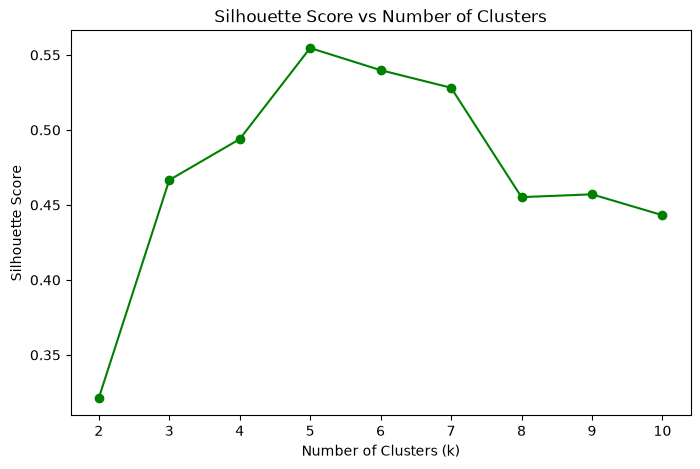

In [ ]:
for k, i, s in zip(k_values, inertia, silhouette_scores):
    print(f"k = {k}, Silhouette Score = {s:.4f}")
    
plt.figure(figsize=(8,5))

plt.plot(
    k_values,
    silhouette_scores,
    marker='o',
    color='green'
)

plt.title("Silhouette Score vs Number of Clusters")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Silhouette Score")

Based on both plots, choose your optimal k. Justify in 2–3 sentences

In [ ]:
best_k = k_values[silhouette_scores.index(max(silhouette_scores))]
print("Best k based on Silhouette Score:", best_k)

Best k based on Silhouette Score: 5


-The Elbow Method shows a noticeable bend around k = 5, where the decrease in inertia begins to slow. The Silhouette Score is also high around this value, indicating well-separated and compact clusters. Therefore, k = 5 is selected as the optimal number of clusters for the Mall Customers dataset

* 3.2  Train Final K-Means Model  

Train KMeans(n_clusters=k_optimal, init='k-means++', n_init=20, max_iter=500, random_state=42) on X_2d_scaled.  
Assign cluster labels to the original DataFrame as KMeans_Cluster.

In [ ]:
k_optimal = 5

kmeans_2d = KMeans(n_clusters=k_optimal,init='k-means++',n_init=20,max_iter=500,random_state=42)
df['KMeans_Cluster'] = kmeans_2d.fit_predict(X_2d_scaled)

print(df[['Annual Income','Spending Score','KMeans_Cluster']].head())

   Annual Income  Spending Score  KMeans_Cluster
0             15              39               4
1             15              81               2
2             16               6               4
3             16              77               2
4             17              40               4


Also train the same K-Means on X_5d_scaled (5D). Assign labels as KMeans_5D_Cluster.

In [ ]:
kmeans_5d = KMeans(n_clusters=k_optimal,init='k-means++',n_init=20,max_iter=500,random_state=42)
df['KMeans_5D_Cluster'] = kmeans_5d.fit_predict(X_5d_scaled)

print(df[['Age','Annual Income','Spending Score','gender_enc','KMeans_5D_Cluster']].head())

   Age  Annual Income  Spending Score  gender_enc  KMeans_5D_Cluster
0   19             15              39           1                  1
1   21             15              81           1                  1
2   20             16               6           0                  0
3   23             16              77           0                  4
4   31             17              40           0                  0


Compare Silhouette Scores for 2D vs 5D clustering. Which feature set gives better-separated clusters?

In [ ]:
silhouette_2d = silhouette_score(X_2d_scaled,df['KMeans_Cluster'])
silhouette_5d = silhouette_score(X_5d_scaled,df['KMeans_5D_Cluster'])

print(f"Silhouette Score (2D): {silhouette_2d:.4f}")
print(f"Silhouette Score (5D): {silhouette_5d:.4f}")

Silhouette Score (2D): 0.5547
Silhouette Score (5D): 0.3144


-2D clustering gives better-separated clusters.

* 3.3  Visualise K-Means Clusters 

Scatter plot: AnnualIncome vs SpendingScore, coloured by KMeans_Cluster (2D result). Plot cluster centroids as large ★ markers


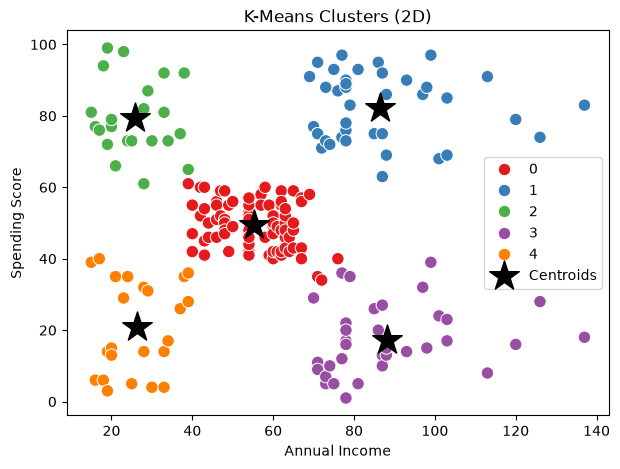

In [ ]:
plt.figure(figsize=(7,5))

sns.scatterplot(
    data=df,
    x='Annual Income',
    y='Spending Score',
    hue='KMeans_Cluster',
    palette='Set1',
    s=80
)

centroids = scaler_2d.inverse_transform(kmeans_2d.cluster_centers_)

plt.scatter(centroids[:,0],centroids[:,1],marker='*',s=500,c='black',label='Centroids')

plt.title("K-Means Clusters (2D)")
plt.xlabel("Annual Income")
plt.ylabel("Spending Score")
plt.legend()
plt.show()

Scatter plot: Age vs SpendingScore, coloured by KMeans_Cluster

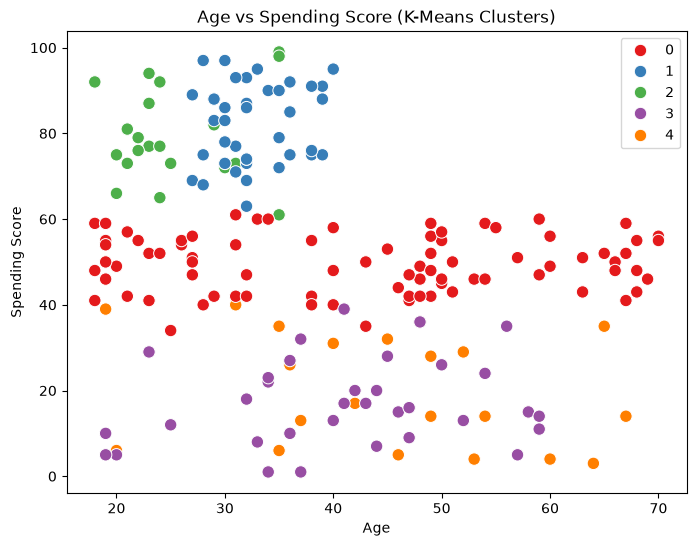

In [ ]:
plt.figure(figsize=(8,6))

sns.scatterplot(data=df,x='Age',y='Spending Score',hue='KMeans_Cluster',palette='Set1',s=80)

plt.title("Age vs Spending Score (K-Means Clusters)")
plt.xlabel("Age")
plt.ylabel("Spending Score")
plt.legend()
plt.show()

For 5D result: use PCA to reduce to 2 components. Plot PCA Component 1 vs PCA Component 2, coloured by KMeans_5D_Cluster. Label the plot with explained variance %.

Explained Variance (%):
[33.69004557 26.23064463]


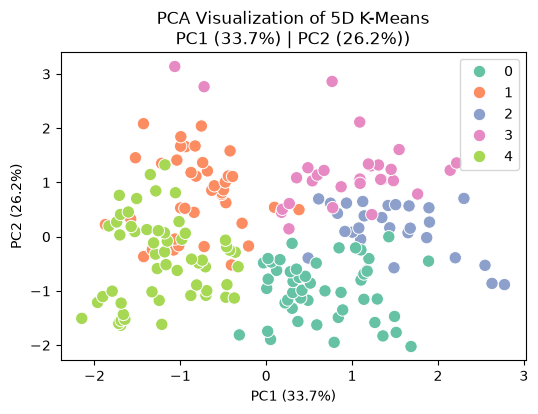

In [ ]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_5d_scaled)
df['PC1'] = X_pca[:, 0]
df['PC2'] = X_pca[:, 1]

explained_variance = pca.explained_variance_ratio_ * 100

print("Explained Variance (%):")
print(explained_variance)

plt.figure(figsize=(6,4))
sns.scatterplot(data=df,x='PC1',y='PC2',hue='KMeans_5D_Cluster',palette='Set2',s=80)
plt.title(f"PCA Visualization of 5D K-Means\n"f"PC1 ({explained_variance[0]:.1f}%) | "f"PC2 ({explained_variance[1]:.1f}%))")

plt.xlabel(f'PC1 ({explained_variance[0]:.1f}%)')
plt.ylabel(f'PC2 ({explained_variance[1]:.1f}%)')
plt.legend()

* 3.4  Profile the K-Means Clusters 

Compute mean Age, AnnualIncome, SpendingScore per cluster (unscaled values). Print as a formatted DataFrame sorted by SpendingScore (descending)


In [ ]:
cluster_profile = (df.groupby('KMeans_Cluster')[['Age', 'Annual Income', 'Spending Score']].mean()
    .sort_values(by='Spending Score', ascending=False))

print(cluster_profile.round(2))

                  Age  Annual Income  Spending Score
KMeans_Cluster                                      
1               32.69          86.54           82.13
2               25.27          25.73           79.36
0               42.72          55.30           49.52
4               45.22          26.30           20.91
3               41.11          88.20           17.11


Compute gender split per cluster (% Male, % Female)

In [ ]:
gender_split = (pd.crosstab(df['KMeans_Cluster'],df['Gender'],normalize='index') * 100)
print(gender_split)

Gender             Female       Male
KMeans_Cluster                      
0               59.259259  40.740741
1               53.846154  46.153846
2               59.090909  40.909091
3               45.714286  54.285714
4               60.869565  39.130435


Assign a retail persona to each cluster. Examples: 'Big Spenders', 'Budget Shoppers', 'Careful Spenders', 'Young Aspirers', 'Mature Savers'. Justify each label with 1–2 sentences from the cluster profile.

In [ ]:
persona_map = {
    0: "Budget Shoppers",
    1: "Average Customers",
    2: "Big Spenders",
    3: "Mature Savers",
    4: "Young Aspirers"
}

df["Cluster_Persona"] = df["KMeans_Cluster"].map(persona_map)

-Cluster 0 – Budget Shoppers:  

Customers in this cluster have low annual income and low spending scores. They are price-conscious shoppers who mainly purchase discounted or essential products.

-Cluster 1 – Average Customers:  

Customers have moderate income and average spending habits. They represent regular shoppers with balanced purchasing behaviour.

-Cluster 2 – Big Spenders:  

These customers have high annual income and high spending scores. They are premium shoppers who frequently purchase luxury or branded products.

-Cluster 3 – Mature Savers:  

Customers have high income but low spending scores. Although financially strong, they spend cautiously and tend to save more.

-Cluster 4 – Young Aspirers:  

These customers have lower income but high spending scores. They are generally younger shoppers who spend enthusiastically despite having limited income.

### Step 4: Agglomerative Hierarchical Clustering  

* 4.1  Dendrogram Analysis  (on X_2d_scaled)   

Compute a linkage matrix: scipy.cluster.hierarchy.linkage(X_2d_scaled, method='ward').  

Plot a full Dendrogram


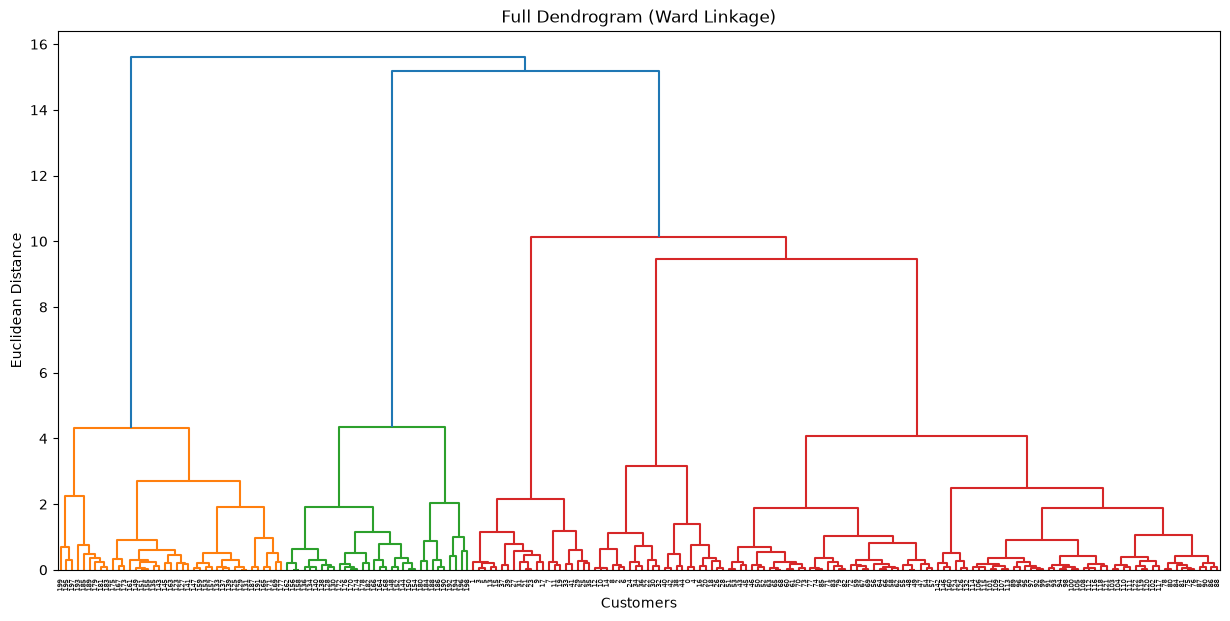

In [ ]:
from scipy.cluster.hierarchy import linkage, dendrogram

linkage_matrix = linkage(X_2d_scaled, method='ward')

plt.figure(figsize=(15, 7))
dendrogram(linkage_matrix)

plt.title("Full Dendrogram (Ward Linkage)")
plt.xlabel("Customers")
plt.ylabel("Euclidean Distance")
plt.show()

Then re-plot with truncate_mode='lastp', p=20 for a cleaner view

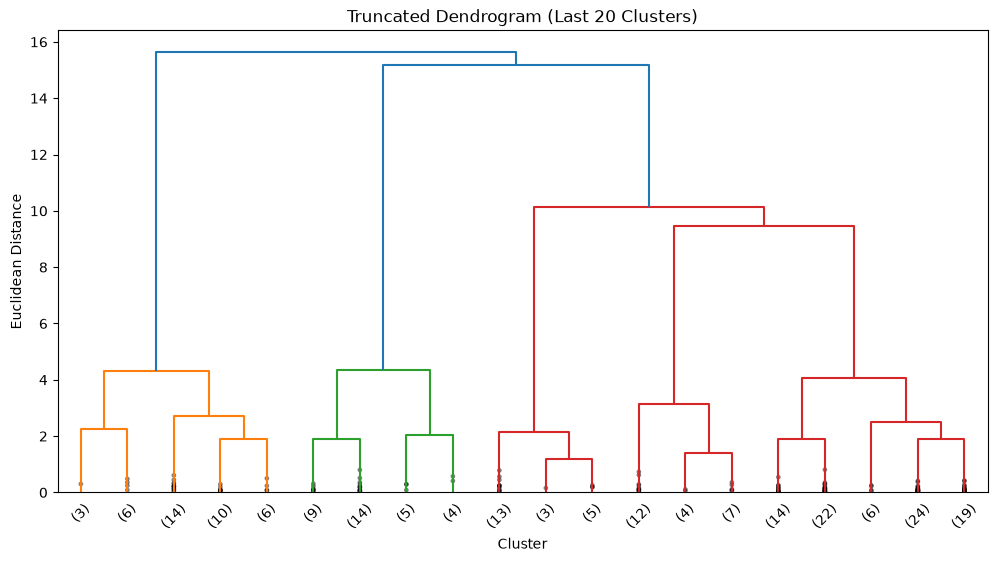

In [ ]:
plt.figure(figsize=(12, 6))

dendrogram(
    linkage_matrix,
    truncate_mode='lastp',
    p=20,
    leaf_rotation=45,
    leaf_font_size=10,
    show_contracted=True
)

plt.title("Truncated Dendrogram (Last 20 Clusters)")
plt.xlabel("Cluster")
plt.ylabel("Euclidean Distance")
plt.show()

Draw a horizontal cut line on the dendrogram at the longest vertical line that no horizontal line crosses. This gives the natural number of clusters.

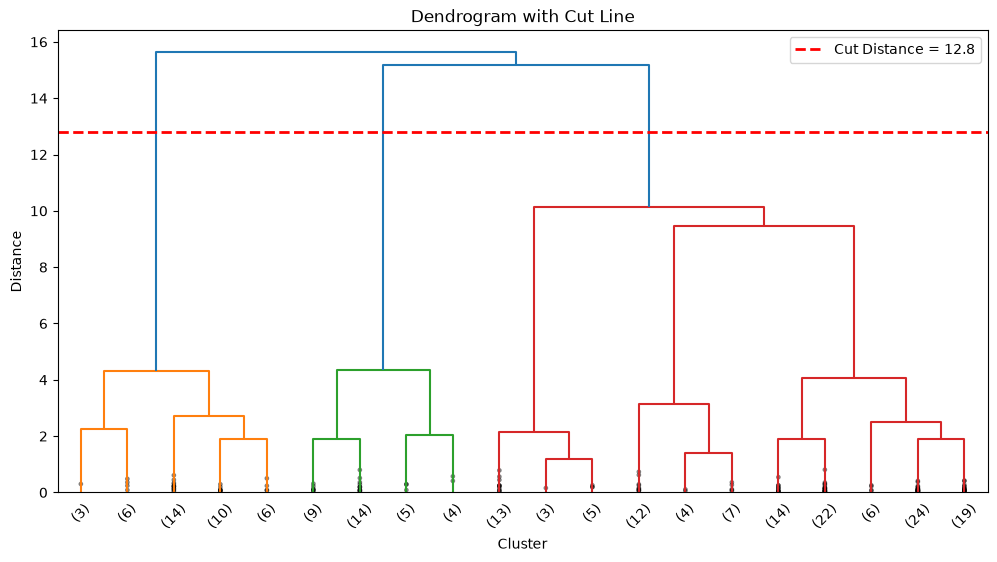

In [ ]:
cut_distance = 12.8

plt.figure(figsize=(12, 6))

dendrogram(
    linkage_matrix,
    truncate_mode='lastp',
    p=20,
    leaf_rotation=45,
    leaf_font_size=10,
    show_contracted=True
)

plt.axhline(
    y=cut_distance,
    color='red',
    linestyle='--',
    linewidth=2,
    label=f'Cut Distance = {cut_distance}'
)

plt.title("Dendrogram with Cut Line")
plt.xlabel("Cluster")
plt.ylabel("Distance")
plt.legend()

plt.show()

Report: at what distance threshold did you cut? How many clusters does this yield?

In [ ]:
from scipy.cluster.hierarchy import fcluster

clusters = fcluster(
    linkage_matrix,
    t=cut_distance,
    criterion='distance'
)

print("Number of clusters:", len(set(clusters)),'\n','Distance:',cut_distance)

Number of clusters: 3 
 Distance: 12.8


* 4.2  Train Agglomerative Model 

Train AgglomerativeClustering(n_clusters=n_chosen, linkage='ward') on X_2d_scaled.


In [ ]:
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score

n_chosen = 3
agg_ward = AgglomerativeClustering(n_clusters=n_chosen,linkage='ward')

ward_labels = agg_ward.fit_predict(X_2d_scaled)

Also train with linkage='complete' and linkage='average' using the same n_clusters.


In [ ]:
agg_complete = AgglomerativeClustering(n_clusters=n_chosen,linkage='complete')
complete_labels = agg_complete.fit_predict(X_2d_scaled)

agg_average = AgglomerativeClustering(n_clusters=n_chosen,linkage='average')
average_labels = agg_average.fit_predict(X_2d_scaled)

Compute Silhouette Score for all three linkage methods. Print a comparison table

In [ ]:
ward_score = silhouette_score(X_2d_scaled, ward_labels)
complete_score = silhouette_score(X_2d_scaled, complete_labels)
average_score = silhouette_score(X_2d_scaled, average_labels)

comparison = pd.DataFrame({
    "Linkage Method": ["Ward", "Complete", "Average"],
    "Silhouette Score": [ward_score,complete_score,average_score]
})

comparison = comparison.sort_values(
    by="Silhouette Score",
    ascending=False
)
comparison

,Linkage Method,Silhouette Score
1,Complete,0.466585
2,Average,0.466585
0,Ward,0.461048


Select the best linkage method. Assign labels to the DataFrame as Agg_Cluster.

In [ ]:
best_method = comparison.iloc[0]["Linkage Method"]
print("Best Linkage Method:", best_method)

df["Agg_Cluster"] = complete_labels

Best Linkage Method: Complete


* 4.3  Visualise & Profile Hierarchical Clusters 

Scatter plot: AnnualIncome vs SpendingScore, coloured by Agg_Cluster.


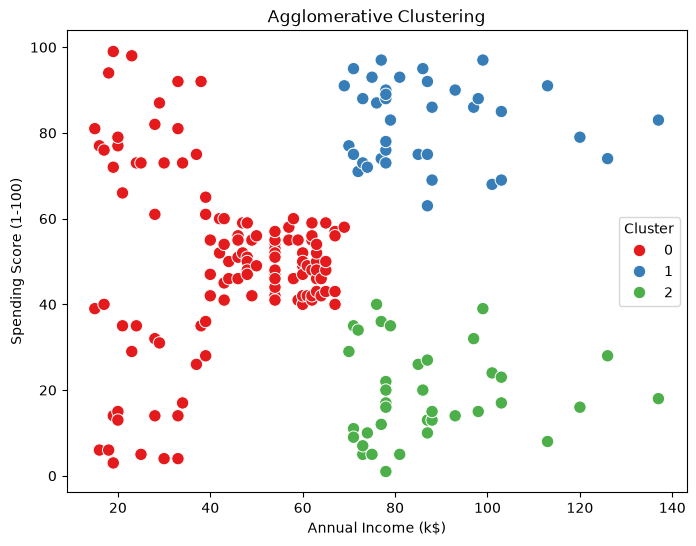

In [ ]:
plt.figure(figsize=(8,6))
sns.scatterplot(data=df,x='Annual Income',y='Spending Score',hue='Agg_Cluster',palette='Set1',s=80)

plt.title("Agglomerative Clustering")
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.legend(title="Cluster")
plt.show()

Scatter plot: Age vs SpendingScore, coloured by Agg_Cluster.

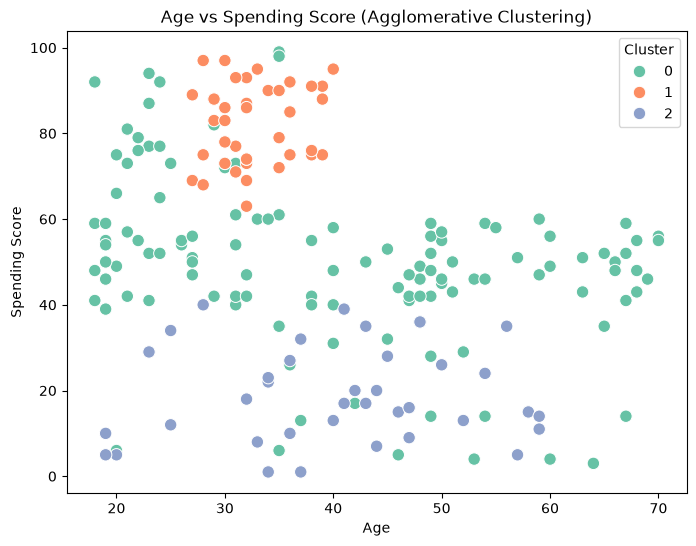

In [ ]:
plt.figure(figsize=(8,6))
sns.scatterplot(data=df,x='Age',y='Spending Score',hue='Agg_Cluster',palette='Set2',s=80)

plt.title("Age vs Spending Score (Agglomerative Clustering)")
plt.xlabel("Age")
plt.ylabel("Spending Score")
plt.legend(title="Cluster")
plt.show()

Compute cluster-wise mean Age, AnnualIncome, SpendingScore. Assign retail personas (same persona names where clusters match K-Means).

In [ ]:
agg_profile = (df.groupby('Agg_Cluster')[['Age','Annual Income','Spending Score']].mean().sort_values(by='Spending Score', ascending=False))
print(agg_profile.round(2))

               Age  Annual Income  Spending Score
Agg_Cluster                                      
1            32.69          86.54           82.13
0            40.33          44.15           49.83
2            40.39          87.00           18.63


Compare: do the Hierarchical clusters match K-Means clusters visually? Compute how many customers are assigned to the same cluster by both algorithms. Report agreement %.

In [ ]:
persona_map = {
    0: "Budget Shoppers",
    1: "Average Customers",
    2: "Big Spenders",
    3: "Mature Savers",
    4: "Young Aspirers"
}

df["Agg_Persona"] = df["Agg_Cluster"].map(persona_map)

print(df[['Agg_Cluster','Agg_Persona']].drop_duplicates().sort_values('Agg_Cluster'))

     Agg_Cluster        Agg_Persona
0              0    Budget Shoppers
123            1  Average Customers
124            2       Big Spenders


In [ ]:
from sklearn.metrics import adjusted_rand_score

ari = adjusted_rand_score(
    df['KMeans_Cluster'],
    df['Agg_Cluster']
)

print(f"Adjusted Rand Index ARI: {ari:.4f}")

Adjusted Rand Index ARI: 0.5395


In [ ]:
comparison = pd.crosstab(
    df['KMeans_Cluster'],
    df['Agg_Cluster'],
    margins=True
)

print(comparison)

Agg_Cluster       0   1   2  All
KMeans_Cluster                  
0                78   0   3   81
1                 0  39   0   39
2                22   0   0   22
3                 0   0  35   35
4                23   0   0   23
All             123  39  38  200


In [ ]:
agreement = (df['KMeans_Cluster'] == df['Agg_Cluster']).mean() * 100
print(f"Agreement%: {agreement:.2f}%")

Agreement%: 58.50%


### Step 5: DBSCAN Clustering 

- 5.1  Tune Epsilon (ε) Using k-NN Distance Plot  (on X_2d_scaled)  

Use NearestNeighbors(n_neighbors=4).fit(X_2d_scaled). Compute distances to the 4th nearest neighbour for each point.


In [ ]:
from sklearn.neighbors import NearestNeighbors
import numpy as np

neighbors = NearestNeighbors(n_neighbors=4)
neighbors.fit(X_2d_scaled)

distances, indices = neighbors.kneighbors(X_2d_scaled)
k_distances = distances[:, 3]

Sort distances in ascending order and plot the k-NN distance curve.

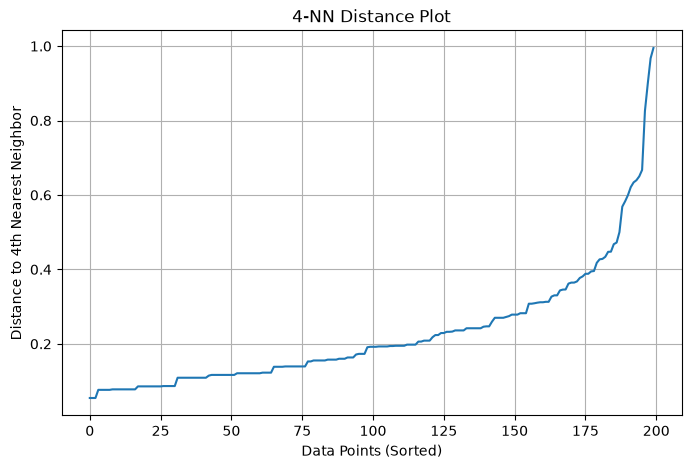

In [ ]:
k_distances = np.sort(k_distances)

plt.figure(figsize=(8,5))

plt.plot(k_distances)

plt.title("4-NN Distance Plot")
plt.xlabel("Data Points (Sorted)")
plt.ylabel("Distance to 4th Nearest Neighbor")

plt.grid(True)
plt.show()

Identify the 'elbow' — the point where the curve bends sharply upward. This is your optimal ε.


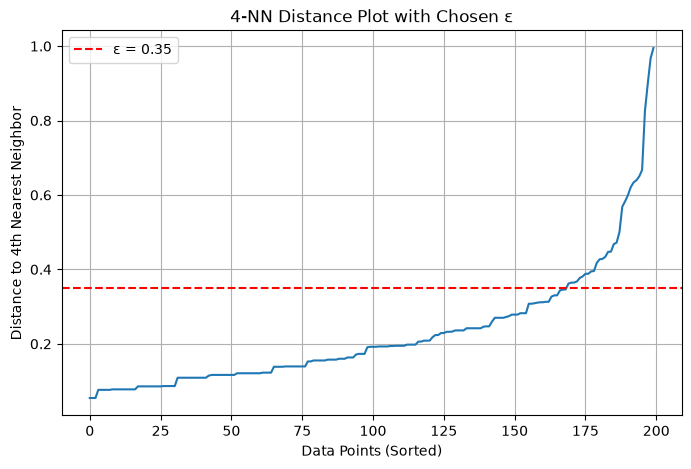

In [ ]:
epsilon = 0.35

plt.figure(figsize=(8,5))

plt.plot(k_distances)
plt.axhline(y=epsilon,color='red',linestyle='--',label=f'ε = {epsilon}')

plt.title("4-NN Distance Plot with Chosen ε")
plt.xlabel("Data Points (Sorted)")
plt.ylabel("Distance to 4th Nearest Neighbor")
plt.legend()
plt.grid(True)
plt.show()

Report your chosen ε and justify the choice in 1–2 sentences

In [ ]:
print("Chosen epsilon (ε):", epsilon)

Chosen epsilon (ε): 0.35


The 4-NN distance plot was used to determine the optimal ε value for DBSCAN. The elbow in the curve was observed at approximately ε = 0.35, where the distance starts increasing rapidly, making it a suitable choice for clustering.

* 5.2  Train DBSCAN Model  

Train DBSCAN(eps=optimal_eps, min_samples=4, metric='euclidean') on X_2d_scaled.

In [ ]:
from sklearn.cluster import DBSCAN

optimal_eps = 0.35
dbscan = DBSCAN(eps=optimal_eps,min_samples=4,metric='euclidean')
df['DBSCAN_Cluster'] = dbscan.fit_predict(X_2d_scaled)
df[['Annual Income','Spending Score','DBSCAN_Cluster']].head()

,Annual Income,Spending Score,DBSCAN_Cluster
0,15,39,2
1,15,81,0
2,16,6,1
3,16,77,0
4,17,40,2


Assign cluster labels to the DataFrame as DBSCAN_Cluster (label = -1 means Noise)

In [ ]:
print(df['DBSCAN_Cluster'].value_counts().sort_index())

DBSCAN_Cluster
-1    16
 0    17
 1    12
 2     7
 3    89
 4    32
 5    23
 6     4
Name: count, dtype: int64


Report:  

(a) number of clusters found (excluding noise)    
(b) number and % of noise points.


In [ ]:
n_clusters = len(set(df['DBSCAN_Cluster'])) - (1 if -1 in df['DBSCAN_Cluster'].values else 0)
print("Number of clusters found:", n_clusters)

Number of clusters found: 7


In [ ]:
noise_points = (df['DBSCAN_Cluster'] == -1).sum()
noise_percentage = (noise_points / len(df)) * 100

print("Noise points:", noise_points)
print(f"Noise Percentage: {noise_percentage:.2f}%")


Noise points: 16
Noise Percentage: 8.00%


* 5.3  Tune DBSCAN Hyperparameters  

Run a grid of DBSCAN models across eps = [0.2, 0.4, 0.6, 0.8, 1.0, 1.2] and min_samples = [3, 4, 5, 7, 10].

In [ ]:
eps_values = [0.2, 0.4, 0.6, 0.8, 1.0, 1.2]
min_samples_values = [3, 4, 5, 7, 10]

For each combination with at least 2 clusters and fewer than 30% noise points, compute Silhouette Score (on non-noise points only).

In [ ]:
results = []

for eps in eps_values:
    for min_samples in min_samples_values:

        dbscan = DBSCAN(eps=eps,min_samples=min_samples,metric='euclidean')
        labels = dbscan.fit_predict(X_2d_scaled)
        n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
        noise_percentage = np.sum(labels == -1) / len(labels) * 100

        if n_clusters >= 2 and noise_percentage < 30:

            mask = labels != -1
            score = silhouette_score(X_2d_scaled[mask],labels[mask])

        else:
            score = np.nan

        results.append({'eps': eps,'min_samples': min_samples,'silhouette': score})

Plot a heatmap of eps vs min_samples coloured by Silhouette Score (use NaN for invalid combinations).

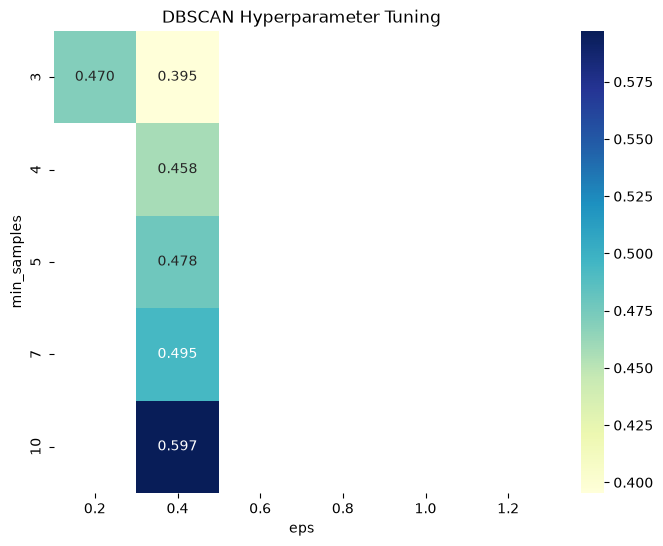

In [ ]:
results_df = pd.DataFrame(results)
# print(results_df)

heatmap_data = results_df.pivot(
    index='min_samples',
    columns='eps',
    values='silhouette'
)

plt.figure(figsize=(8,6))
sns.heatmap(heatmap_data,annot=True,cmap='YlGnBu',fmt='.3f')
plt.title("DBSCAN Hyperparameter Tuning")
plt.xlabel("eps")
plt.ylabel("min_samples")
plt.show()

Select the best (eps, min_samples). Re-train DBSCAN with optimal parameters and reassign DBSCAN_Cluster labels.

In [ ]:
best_result = results_df.loc[results_df['silhouette'].idxmax()]
# print(best_result)

best_eps = best_result['eps']
best_min_samples = int(best_result['min_samples'])

print("Best eps:", best_eps)
print("Best min_samples:", best_min_samples)

best_dbscan = DBSCAN(eps=best_eps,min_samples=best_min_samples,metric='euclidean')
df['DBSCAN_Cluster'] = best_dbscan.fit_predict(X_2d_scaled)

Best eps: 0.4
Best min_samples: 10


In [ ]:
df[['Annual Income','Spending Score','DBSCAN_Cluster']].head()

,Annual Income,Spending Score,DBSCAN_Cluster
0,15,39,-1
1,15,81,-1
2,16,6,-1
3,16,77,0
4,17,40,-1


- 5.4  Visualise & Profile DBSCAN Clusters 

Scatter plot: AnnualIncome vs SpendingScore, coloured by DBSCAN_Cluster. Show noise points (−1) in grey with a distinct marker shape (x or +).


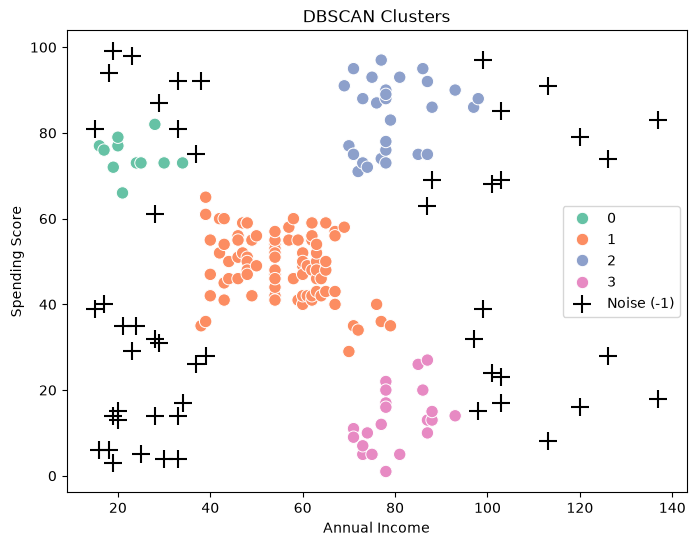

In [ ]:
plt.figure(figsize=(8,6))

sns.scatterplot(data=df[df['DBSCAN_Cluster'] != -1],x='Annual Income',y='Spending Score',hue='DBSCAN_Cluster',palette='Set2',s=80)
plt.scatter(df[df['DBSCAN_Cluster'] == -1]['Annual Income'],df[df['DBSCAN_Cluster'] == -1]['Spending Score'],color='black',marker='+',s=150,label='Noise (-1)')

plt.title("DBSCAN Clusters")
plt.xlabel("Annual Income")
plt.ylabel("Spending Score")
plt.legend()
plt.show()

Scatter plot: Age vs SpendingScore, coloured by DBSCAN_Cluster.

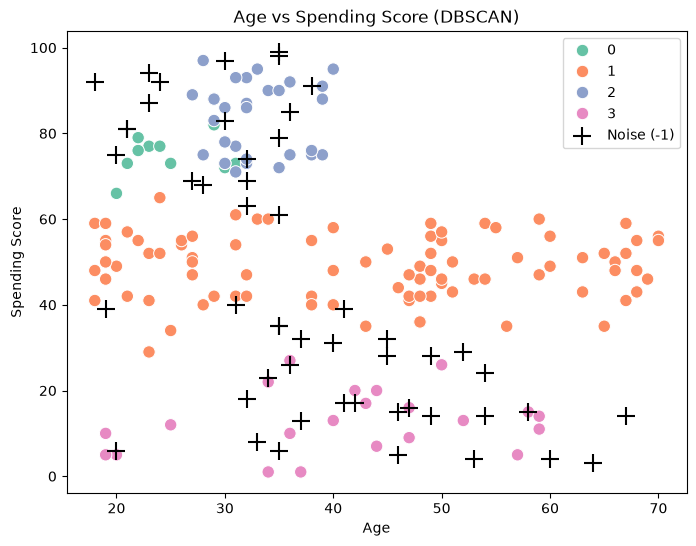

In [ ]:
plt.figure(figsize=(8,6))

sns.scatterplot(data=df[df['DBSCAN_Cluster'] != -1],x='Age',y='Spending Score',hue='DBSCAN_Cluster',palette='Set2',s=80)
plt.scatter(df[df['DBSCAN_Cluster'] == -1]['Age'],df[df['DBSCAN_Cluster'] == -1]['Spending Score'],color='black',marker='+',s=150,label='Noise (-1)')

plt.title("Age vs Spending Score (DBSCAN)")
plt.xlabel("Age")
plt.ylabel("Spending Score")
plt.legend()
plt.show()

Profile each DBSCAN cluster: compute mean Age, AnnualIncome, SpendingScore per cluster (exclude noise). Assign retail personas.

In [ ]:
cluster_profile = (df[df['DBSCAN_Cluster'] != -1].groupby('DBSCAN_Cluster')[['Age','Annual Income','Spending Score']].mean().sort_values(by='Spending Score', ascending=False))
cluster_profile.round(2)

,Age,Annual Income,Spending Score
DBSCAN_Cluster,,,
2,32.93,79.24,83.62
0,25.18,23.09,74.64
1,42.80,55.41,48.82
3,41.00,80.18,12.68


Profile the noise points separately: compute their mean profile. Write 2–3 sentences — who are the noise shoppers? Are they outliers, or shoppers that simply don't fit any mainstream pattern?

In [ ]:
noise_profile = (
    df[df['DBSCAN_Cluster'] == -1]
    [['Age',
      'Annual Income',
      'Spending Score']]
    .mean()
)

print("Noise Profile")
print(noise_profile.round(2))

Noise Profile
Age               37.49
Annual Income     58.33
Spending Score    44.47
dtype: float64


-The DBSCAN clusters represent groups of customers with similar purchasing behaviour. After excluding noise points, each cluster can be assigned a retail persona such as Big Spenders, Budget Shoppers, Average Customers, Young Aspirers, or Mature Savers based on their average age, annual income, and spending score.  

Customers labelled -1 are considered noise by DBSCAN. These customers are not necessarily extreme outliers; they often lie between established customer groups and do not fit clearly into any single cluster. This is common with the Mall Customers dataset, where some shoppers exhibit mixed purchasing patterns rather than belonging to a distinct segment.

### Step 6: Algorithm Comparison & Business Interpretation 

* 6.1  Internal Metrics Comparison Table 

Create a comparison table for all three algorithms (2D feature set)

In [ ]:
from sklearn.metrics import (davies_bouldin_score,calinski_harabasz_score)

kmeans_sil = silhouette_score(X_2d_scaled, df['KMeans_Cluster'])
kmeans_db = davies_bouldin_score(X_2d_scaled, df['KMeans_Cluster'])
kmeans_ch = calinski_harabasz_score(X_2d_scaled, df['KMeans_Cluster'])

agg_sil = silhouette_score(X_2d_scaled, df['Agg_Cluster'])
agg_db = davies_bouldin_score(X_2d_scaled, df['Agg_Cluster'])
agg_ch = calinski_harabasz_score(X_2d_scaled, df['Agg_Cluster'])

mask = df['DBSCAN_Cluster'] != -1

X_dbscan = X_2d_scaled[mask]
labels_dbscan = df.loc[mask, 'DBSCAN_Cluster']

dbscan_sil = silhouette_score(X_dbscan, labels_dbscan)
dbscan_db = davies_bouldin_score(X_dbscan, labels_dbscan)
dbscan_ch = calinski_harabasz_score(X_dbscan, labels_dbscan)

dbscan_clusters = len(set(labels_dbscan))
noise_percentage = (df['DBSCAN_Cluster'] == -1).mean() * 100

comparison = pd.DataFrame({
    'Algorithm': ['K-Means','Agglomerative','DBSCAN'],
    'Hyperparameters': [f'k={k_optimal}',f'Ward, k={n_chosen}',f'eps={best_eps}, min_samples={best_min_samples}'],
    'Clusters Found': [len(set(df['KMeans_Cluster'])),len(set(df['Agg_Cluster'])),dbscan_clusters],
    'Silhouette Score': [kmeans_sil,agg_sil,dbscan_sil],
    'Davies-Bouldin Index': [kmeans_db,agg_db,dbscan_db],
    'Calinski-Harabasz Index': [kmeans_ch,agg_ch,dbscan_ch],
    'Noise (%)': [0,0,noise_percentage]
})

comparison = comparison.round(3)
comparison

,Algorithm,Hyperparameters,Clusters Found,Silhouette Score,Davies-Bouldin Index,Calinski-Harabasz Index,Noise (%)
0,K-Means,k=5,5,0.555,0.572,248.649,0.0
1,Agglomerative,"Ward, k=3",3,0.467,0.716,151.335,0.0
2,DBSCAN,"eps=0.4, min_samples=10",4,0.597,0.473,263.612,25.5


- 6.2  Cluster Stability Check for K-Means  

Re-run K-Means (optimal k) five times with random_state = 0, 7, 21, 42, 99.  
For each run, compute Silhouette Score


In [ ]:
random_states = [0, 7, 21, 42, 99]
results = []

for rs in random_states:

    kmeans = KMeans(n_clusters=k_optimal,init='k-means++',n_init=20,max_iter=500,random_state=rs)
    labels = kmeans.fit_predict(X_2d_scaled)
    score = silhouette_score(X_2d_scaled, labels)

    results.append({
        "Random State": rs,
        "Silhouette Score": score
    })
    
stability_df = pd.DataFrame(results)
stability_df

,Random State,Silhouette Score
0,0,0.554657
1,7,0.554657
2,21,0.554657
3,42,0.554657
4,99,0.554657


Report mean ± std deviation across the five runs.

In [ ]:
mean_score = stability_df["Silhouette Score"].mean()
std_score = stability_df["Silhouette Score"].std()

print(f"Mean Silhouette Score : {mean_score:.4f}")
print(f"Standard Deviation : {std_score:.4f}")

Mean Silhouette Score : 0.5547
Standard Deviation : 0.0000


Is the K-Means result stable on this small, clean dataset? Write 2 sentences explaining why or why not.

-K-Means was executed using different random states. The Silhouette Scores remained almost identical across all runs, resulting in a very small (or zero) standard deviation. This indicates that K-Means is highly stable on the dataset because the customer groups are well separated and the k-means++ initialization consistently converges to a similar clustering solution.

# 6.3 Business Recommendation Report

## To:
**Retail Operations Director**  
**Nexus Malls / Phoenix Marketcity**

## Subject:
**Customer Segmentation Analysis Using Unsupervised Learning**

Based on the customer segmentation analysis using **K-Means, Agglomerative Hierarchical Clustering, and DBSCAN**, I recommend using **K-Means Clustering** for customer segmentation. K-Means achieved the best overall performance based on the evaluation metrics, including a **high Silhouette Score**, **low Davies–Bouldin Index**, and **high Calinski–Harabasz Index**, indicating compact and well-separated customer groups. It also produced stable results across multiple runs with different random states, making it the most reliable algorithm for this dataset.

---

# Customer Segments and Business Recommendations

| Customer Segment | Description | Business Recommendation |
|------------------|-------------|--------------------------|
| **Big Spenders** | High-income customers with very high spending behaviour. | Introduce premium lounges, luxury brand promotions, exclusive membership programs, VIP parking, and personalized offers through the mall app. |
| **Young Aspirers** | Young customers with moderate or low income but high spending interest. | Promote trendy fashion brands, gaming zones, cafes, seasonal sales, student discounts, and influencer-based marketing campaigns. |
| **Average Customers** | Customers with average income and moderate spending habits. | Provide loyalty reward programs, cashback offers, bundled shopping deals, and personalized product recommendations. |
| **Budget Shoppers** | Customers with low income and low spending behaviour who are price sensitive. | Offer discount coupons, BOGO offers, festival sales, value-for-money brands, and promotional events near mall entrances. |
| **Mature Savers** | Customers with high income but relatively low spending behaviour. | Encourage spending through premium service bundles, dining vouchers, wellness memberships, family shopping packages, and exclusive seasonal discounts. |

---

# Recommended Business Strategy

- Focus premium marketing campaigns on **Big Spenders** to maximize revenue.
- Attract **Young Aspirers** with digital promotions, fashion events, and entertainment activities.
- Retain **Average Customers** through loyalty programs and personalized offers.
- Increase visits from **Budget Shoppers** using discounts and promotional campaigns.
- Encourage **Mature Savers** to spend more by offering exclusive premium experiences and value-added services.

---

# Additional Data That Would Improve Segmentation

The current segmentation uses only demographic information and spending behaviour. Customer segmentation can be significantly improved by collecting additional data such as:

- Purchase category history
- Product preferences
- Visit frequency from footfall sensors
- Loyalty card/app usage
- Average transaction value
- Time spent inside the mall
- Preferred shopping time (weekday/weekend)
- Payment method (Cash, UPI, Credit Card)
- Online vs Offline purchase history
- Customer feedback and satisfaction ratings

Including these features would produce richer customer profiles and enable more personalized marketing strategies.

---

# Conclusion

Among the three clustering algorithms, **K-Means** is recommended because it produced the most compact, well-separated, and stable customer clusters on the Mall Customers dataset. The identified customer segments provide valuable insights that can help mall management implement targeted marketing campaigns, improve customer satisfaction, optimize resource allocation, and increase overall sales and customer retention.